# Sales are not demand: Store 014's records

The runnable companion to [Retail and grocery](https://kvinayakpai.github.io/domain-series/retail/) and its [technical companion](https://kvinayakpai.github.io/domain-series/retail/technical/).
Everything here uses Store 014's downloadable records: a fictional supermarket in Bengaluru, simulated hour by hour
through June 2026. The answer key is read only at the end of each section, to score what the records gave us.

Runs in a few seconds. Needs `duckdb`, `pandas`, `numpy` and `matplotlib` (all preinstalled in Colab).

In [1]:
import json, math, os, urllib.request
from datetime import date, timedelta

import duckdb
import numpy as np
import pandas as pd

DATA = os.environ.get("STORE014_DATA", "https://kvinayakpai.github.io/domain-series/data/india-grocery/")
FILES = {
    "products": "products.csv", "pos_lines": "pos-lines-may-june.csv", "daily_sales": "daily-sales-june.csv",
    "inventory_book": "inventory-book-june.csv", "forecasts": "forecasts-june.csv",
    "store_orders": "store-orders-june.csv", "goods_receipts": "goods-receipts-june.csv",
    "stock_counts": "stock-counts-june.csv", "shelf_audits": "shelf-audits-june.csv",
    "write_offs": "write-offs-june.csv", "fresh_deliveries": "fresh-deliveries-june.csv",
}
TIMES = {"pos_lines": ["bill_ts"], "goods_receipts": ["received_ts"], "stock_counts": ["count_ts"],
         "shelf_audits": ["audit_ts"], "store_orders": ["created_ts"], "fresh_deliveries": ["delivery_ts"]}
DATES = {"daily_sales", "inventory_book", "forecasts", "write_offs"}

con = duckdb.connect()
tables = {}
for name, file in FILES.items():
    df = pd.read_csv(DATA + file, parse_dates=TIMES.get(name, []))
    if name in DATES:
        df["date"] = pd.to_datetime(df["date"]).dt.date
    tables[name] = df
    con.register(name, df)
def read_json(path):
    if path.startswith("http"):
        with urllib.request.urlopen(path) as f:
            return json.load(f)
    with open(path) as f:
        return json.load(f)

KEY = read_json(DATA + "answer-key-retail.json")   # for scoring only

def q(sql):
    return con.execute(sql).df()

HERO = "ATTA-WW-5KG"
OPEN_HOURS = list(range(7, 22))                     # hour h covers h:00 to h+1:00
MAY_DAYS = [date(2026, 5, 4) + timedelta(days=i) for i in range(28)]
JUNE_DAYS = [date(2026, 6, 1) + timedelta(days=i) for i in range(28)]
DAYS = MAY_DAYS + JUNE_DAYS
DC = list(tables["products"].query("flow == 'DC'").sku)
{k: len(v) for k, v in tables.items()}

{'products': 11,
 'pos_lines': 35485,
 'daily_sales': 308,
 'inventory_book': 308,
 'forecasts': 196,
 'store_orders': 68,
 'goods_receipts': 70,
 'stock_counts': 25,
 'shelf_audits': 88,
 'write_offs': 34,
 'fresh_deliveries': 112}

## 1. Tests that pass

Twelve data tests, the kind a dbt project ships on day one. A test passes when its query returns no rows.

In [2]:
TESTS = {
 "Till lines: bill and line number are unique":
   "SELECT bill_id, line, count(*) FROM pos_lines GROUP BY ALL HAVING count(*) > 1",
 "Till lines: keys present, quantities and prices positive":
   "SELECT * FROM pos_lines WHERE bill_id IS NULL OR bill_ts IS NULL OR sku_scanned IS NULL OR qty <= 0 OR unit_price <= 0",
 "Till lines: every item and barcode is in the product master":
   "SELECT l.* FROM pos_lines l LEFT JOIN products p ON l.sku_scanned = p.sku AND l.gtin_scanned = p.gtin WHERE p.sku IS NULL",
 "Till lines: line amount is quantity times price":
   "SELECT * FROM pos_lines WHERE abs(line_amount - qty * unit_price) > 0.005",
 "Daily sales reconcile with the till lines": """
   WITH t AS (SELECT CAST(bill_ts AS DATE) AS date, sku_scanned AS sku, sum(qty) AS units FROM pos_lines GROUP BY ALL)
   SELECT d.* FROM daily_sales d LEFT JOIN t ON t.date = d.date AND t.sku = d.sku
   WHERE d.units_sold <> coalesce(t.units, 0)""",
 "Book stock: one row per item per day, never negative": """
   SELECT date, sku, book_on_hand_close FROM inventory_book WHERE book_on_hand_close < 0
   UNION ALL SELECT date, NULL, count(*) FROM inventory_book GROUP BY date HAVING count(*) <> (SELECT count(*) FROM products)""",
 "Book stock: each close is the last close plus receipts, minus sales and write-offs, plus count adjustments": """
   WITH rcv AS (SELECT date, sku, sum(u) AS u FROM (
                  SELECT CAST(received_ts AS DATE) AS date, sku_booked AS sku, units_booked AS u FROM goods_receipts
                  UNION ALL SELECT CAST(delivery_ts AS DATE), sku, units FROM fresh_deliveries) GROUP BY ALL),
        sold AS (SELECT CAST(bill_ts AS DATE) AS date, sku_scanned AS sku, sum(qty) AS u FROM pos_lines GROUP BY ALL),
        wo AS (SELECT date, sku, sum(units) AS u FROM write_offs GROUP BY ALL),
        adj AS (SELECT CAST(count_ts AS DATE) AS date, sku, sum(adjustment) AS u FROM stock_counts
                WHERE hour(count_ts) < 22 GROUP BY ALL)
   SELECT b.date, b.sku, b.book_on_hand_close AS book, prev.book_on_hand_close + coalesce(rcv.u, 0)
          - coalesce(sold.u, 0) - coalesce(wo.u, 0) + coalesce(adj.u, 0) AS rebuilt
   FROM inventory_book b JOIN inventory_book prev ON prev.sku = b.sku AND prev.date = b.date - 1
   LEFT JOIN rcv ON rcv.date = b.date AND rcv.sku = b.sku LEFT JOIN sold ON sold.date = b.date AND sold.sku = b.sku
   LEFT JOIN wo ON wo.date = b.date AND wo.sku = b.sku LEFT JOIN adj ON adj.date = b.date AND adj.sku = b.sku
   WHERE book <> rebuilt""",
 "Forecasts: one row per warehouse item per night, reorder point below order-up-to": """
   SELECT date, count(*) AS items FROM forecasts GROUP BY date
   HAVING count(*) <> (SELECT count(*) FROM products WHERE flow = 'DC') OR max(CASE WHEN reorder_point > order_up_to THEN 1 ELSE 0 END) = 1""",
 "Forecasts: an order goes out only when book plus on-order is at or below the reorder point":
   "SELECT * FROM forecasts WHERE ordered_units > 0 AND book_on_hand + on_order > reorder_point",
 "Store orders: every automatic order matches that night's forecast row": """
   SELECT o.* FROM store_orders o LEFT JOIN forecasts f ON f.sku = o.sku AND f.date = CAST(o.created_ts AS DATE)
   AND f.ordered_units = o.units WHERE o.reason = 'auto' AND f.sku IS NULL""",
 "Goods receipts: every pallet line booked as its shipping notice says":
   "SELECT * FROM goods_receipts WHERE sku_booked <> asn_sku OR units_booked <> asn_units",
 "Shelf audits: one status per item per audit, on shelf or empty": """
   SELECT audit_ts, sku, count(*) FROM shelf_audits GROUP BY ALL HAVING count(*) > 1
   UNION ALL SELECT audit_ts, sku, 1 FROM shelf_audits WHERE status NOT IN ('on shelf', 'empty')""",
}
results = {name: len(q(sql)) for name, sql in TESTS.items()}
for name, bad in results.items():
    print("PASS" if bad == 0 else f"FAIL ({bad} rows)", name)
print(sum(v == 0 for v in results.values()), "of", len(results), "pass")

PASS Till lines: bill and line number are unique
PASS Till lines: keys present, quantities and prices positive
PASS Till lines: every item and barcode is in the product master
PASS Till lines: line amount is quantity times price
PASS Daily sales reconcile with the till lines
FAIL (6 rows) Book stock: one row per item per day, never negative
PASS Book stock: each close is the last close plus receipts, minus sales and write-offs, plus count adjustments
PASS Forecasts: one row per warehouse item per night, reorder point below order-up-to
PASS Forecasts: an order goes out only when book plus on-order is at or below the reorder point
PASS Store orders: every automatic order matches that night's forecast row
PASS Goods receipts: every pallet line booked as its shipping notice says
PASS Shelf audits: one status per item per audit, on shelf or empty
11 of 12 pass


In [3]:
q(TESTS["Book stock: one row per item per day, never negative"])   # the one failure: full-cream milk

,date,sku,book_on_hand_close
0,2026-06-02,MILK-FC-500ML,-5
1,2026-06-09,MILK-FC-500ML,-5
2,2026-06-11,MILK-FC-500ML,-15
3,2026-06-12,MILK-FC-500ML,-12
4,2026-06-13,MILK-FC-500ML,-14
5,2026-06-20,MILK-FC-500ML,-13


## 2. Hourly sales, and the book rebuilt hour by hour

Units per item, per day and open hour, from the till lines; then the book at the end of every June open hour,
rebuilt from the 1 June count, receipts, sales and counts. The rebuild must land on every recorded close.

In [4]:
pl = tables["pos_lines"]
till = {s: np.zeros((len(DAYS), 15)) for s in tables["products"].sku}
for r in pl.assign(d=pl.bill_ts.dt.date, h=pl.bill_ts.dt.hour).groupby(["sku_scanned", "d", "h"]).qty.sum().reset_index().itertuples():
    till[r.sku_scanned][DAYS.index(r.d), OPEN_HOURS.index(r.h)] += r.qty

counts, rcv, wo, books = tables["stock_counts"], tables["goods_receipts"], tables["write_offs"], tables["inventory_book"]
book, all_closes_match = {}, True
for s in DC:
    level = float(counts[(counts.sku == s) & (counts.count_ts.dt.date == JUNE_DAYS[0])].counted.iloc[0])
    arr = np.zeros((28, 15))
    for j, d in enumerate(JUNE_DAYS):
        events = [(t.hour + t.minute / 60, u) for t, u in rcv[(rcv.sku_booked == s) & (rcv.received_ts.dt.date == d)][["received_ts", "units_booked"]].itertuples(index=False)]
        events += [(t.hour + t.minute / 60, a) for t, a in counts[(counts.sku == s) & (counts.count_ts.dt.date == d)][["count_ts", "adjustment"]].itertuples(index=False)
                   if not (j == 0 and t.hour < 7) and t.hour < 22]
        for h_i, h in enumerate(OPEN_HOURS):
            level += sum(u for t, u in events if (h_i == 0 and t < h + 1) or (h_i > 0 and h <= t < h + 1))
            level -= till[s][28 + j, h_i]
            arr[j, h_i] = level
        level -= wo[(wo.sku == s) & (wo.date == d)].units.sum()
        all_closes_match &= level == books[(books.sku == s) & (books.date == d)].book_on_hand_close.iloc[0]
    book[s] = arr
con.register("hourly_book", pd.DataFrame([{"date": d, "hour": h, "sku": s, "book": book[s][j, i]}
                                           for s in DC for j, d in enumerate(JUNE_DAYS) for i, h in enumerate(OPEN_HOURS)]))
print("rebuilt book matches every close:", all_closes_match)

rebuilt book matches every close: True


## 3. Tests that ask about the world

These encode how a store works. All use only the records, and all fail.

In [5]:
empty_with_stock = q("""
  SELECT a.audit_ts, a.sku, b.book FROM shelf_audits a
  JOIN hourly_book b ON b.sku = a.sku AND b.date = CAST(a.audit_ts AS DATE) AND b.hour = hour(a.audit_ts) - 1
  WHERE a.status = 'empty' AND b.book > 0""")
counts_off = q("SELECT * FROM stock_counts WHERE abs(adjustment) > greatest(1, 0.02 * book_before)")
halving = q("""
  SELECT sku, sum(CASE WHEN date BETWEEN '2026-06-01' AND '2026-06-07' THEN units_sold END) AS week1,
              sum(CASE WHEN date BETWEEN '2026-06-08' AND '2026-06-14' THEN units_sold END) AS week2
  FROM daily_sales JOIN products USING (sku) WHERE flow = 'DC' GROUP BY sku HAVING week2 < 0.5 * week1""")
print(len(empty_with_stock), "audits found an empty shelf with stock on the books")
print(len(counts_off), "count lines more than 2% off the book")
display(empty_with_stock, halving)

2 audits found an empty shelf with stock on the books
16 count lines more than 2% off the book


,audit_ts,sku,book
0,2026-06-12 11:00:00,ATTA-WW-5KG,55.0
1,2026-06-05 11:00:00,SUGAR-1KG,70.0


,sku,week1,week2
0,ATTA-WW-5KG,217.0,88.0


## 4. Finding the censored hours

The gap detector from the companion. It learns each item's hourly pattern from May, then flags a run of open hours
with no sales, while the books show stock, once the chance of no sales falls below `alpha`.

In [6]:
def rolling_mean(a, n):
    return np.array([a[max(0, i - n + 1):i + 1].mean() for i in range(len(a))])

daily = {s: till[s].sum(axis=1) for s in DC}                 # May and June
made = {s: rolling_mean(daily[s], 28) for s in DC}           # the store's forecast, made each night at 22:00
fc_csv = tables["forecasts"]
print("rebuilt forecast matches the store's:", all(abs(round(made[r.sku][DAYS.index(r.date)], 2) - r.forecast_units_per_day) < 0.006
                                                    for r in fc_csv.itertuples()))
may = {s: till[s][:28] for s in DC}
june = {s: till[s][28:] for s in DC}
forecast = {s: made[s][27:55] for s in DC}                   # for each June day, the forecast made the night before

def learn_patterns(may):
    """may[sku]: May's till units, shape (28 days, 15 open hours)."""
    weekend = np.array([d.weekday() >= 5 for d in MAY_DAYS])
    out = {}
    for sku, a in may.items():
        per_day = a.sum(axis=1)
        out[sku] = {
            # share of a day's sales in each open hour, lightly smoothed
            "profile": (a.sum(axis=0) + 0.5) / (a.sum() + 0.5 * 15),
            "weekday": per_day[~weekend].mean() / per_day.mean(),
            "weekend": per_day[weekend].mean() / per_day.mean(),
        }
    return out

def detect(sales, book, forecast, patterns, alpha=0.001):
    """Runs of open hours with no sales while the books show stock,
    flagged once the chance of no sales falls below alpha."""
    limit, runs = -math.log(alpha), []
    for sku, p in patterns.items():
        run, expected, flagged, lone = [], 0.0, None, False
        for d, day in enumerate(JUNE_DAYS):
            level = p["weekend"] if day.weekday() >= 5 else p["weekday"]
            for h in range(15):
                units = sales[sku][d, h]
                e = forecast[sku][d] * level * p["profile"][h]
                if flagged and units == 1 and not lone:
                    lone = True                 # one lone scan inside a gap
                    run.append((d, h, e, 1))
                    expected += e
                    continue
                if units > 0 or book[sku][d, h] <= 0:
                    if flagged:                 # a sale, or the books know
                        runs.append(flagged | {"hours": run})
                    run, expected, flagged, lone = [], 0.0, None, False
                    continue
                run.append((d, h, e, 0))
                expected += e
                if flagged is None and expected > limit:  # P(0) < alpha
                    flagged = {"sku": sku, "start": run[0][:2],
                               "flag": (d, h + 1)}
        if flagged:
            runs.append(flagged | {"hours": run})
    return runs

patterns = learn_patterns(may)
runs = detect(june, book, forecast, patterns, alpha=0.001)

def ts(dh):
    d, h = dh
    return f"{JUNE_DAYS[d]}T{OPEN_HOURS[0] + h:02d}:00"

pd.DataFrame([{"sku": r["sku"], "run starts": ts(r["start"]), "flagged": ts(r["flag"]), "open hours": len(r["hours"]),
               "expected sales": round(sum(x[2] for x in r["hours"]), 1)} for r in runs])

rebuilt forecast matches the store's: True


,sku,run starts,flagged,open hours,expected sales
0,ATTA-WW-5KG,2026-06-10T16:00,2026-06-10T19:00,39,68.1
1,ATTA-WW-5KG,2026-06-23T16:00,2026-06-23T20:00,38,60.8
2,ATTA-WW-1KG,2026-06-07T18:00,2026-06-07T20:00,7,16.3
3,ATTA-WW-1KG,2026-06-22T11:00,2026-06-22T16:00,5,7.0
4,RICE-SM-5KG,2026-06-05T18:00,2026-06-05T22:00,5,8.6
5,RICE-SM-5KG,2026-06-21T19:00,2026-06-21T22:00,6,9.8
6,OIL-SUN-1L,2026-06-07T10:00,2026-06-07T15:00,6,10.9
7,OIL-SUN-1L,2026-06-20T10:00,2026-06-20T15:00,6,10.6
8,OIL-SUN-1L,2026-06-25T07:00,2026-06-25T14:00,8,8.9
9,SUGAR-1KG,2026-06-16T19:00,2026-06-17T09:00,6,7.6


Now score the alerts against the answer key: an alert is real if the shelf was empty when it fired; a gap of three open hours or more is found if an alert fired inside it.

In [7]:
episodes = KEY["episodes"]

def open_hours_between(a, b):
    ta, tb = pd.Timestamp(a), pd.Timestamp(b)
    hours, t = 0.0, ta
    while t < tb:
        nxt = min(tb, t.floor("h") + pd.Timedelta(hours=1))
        if 7 <= t.hour < 22:
            hours += (nxt - t).total_seconds() / 3600
        t = nxt
    return hours

def score(flags):
    """flags: list of (sku, flag timestamp)."""
    hit = [next((e for e in episodes if e["sku"] == s and e["start"] <= t <= e["end"]), None) for s, t in flags]
    big = [e for e in episodes if e["empty_open_hours"] >= 3]
    caught = [e for e in big if any(h is e for h in hit)]
    lat = [open_hours_between(e["start"], min(t for (s, t), h in zip(flags, hit) if h is e)) for e in caught]
    return {"alerts": len(flags), "in a real gap": sum(h is not None for h in hit),
            "gaps found": f"{len(caught)} of {len(big)}", "median open hours to alert": round(float(np.median(lat)), 2) if lat else None}

def nightly_rule(n_days):
    closes = books.set_index(["sku", "date"]).book_on_hand_close
    flags = []
    for s in DC:
        for j, d in enumerate(JUNE_DAYS):
            i = 28 + j
            f = made[s][i - 1]
            if f > 0 and (daily[s][i - n_days + 1:i + 1] < 0.25 * f).all() and closes[(s, d)] >= f:
                flags.append((s, f"{d}T22:00"))
    return flags

options = {f"nightly rule, {n} day(s)": score(nightly_rule(n)) for n in (2, 1)}
for a in (0.01, 0.001, 0.0001):
    options[f"hourly, 1 in {round(1 / a):,}"] = score([(r["sku"], ts(r["flag"])) for r in detect(june, book, forecast, patterns, a)])
pd.DataFrame(options).T

,alerts,in a real gap,gaps found,median open hours to alert
"nightly rule, 2 day(s)",3,3,2 of 10,28.85
"nightly rule, 1 day(s)",5,5,2 of 10,13.85
"hourly, 1 in 100",23,7,7 of 10,3.0
"hourly, 1 in 1,000",10,6,6 of 10,3.67
"hourly, 1 in 10,000",3,3,3 of 10,4.2


## 5. Unconstraining demand

Keep the store's 28-day rule, change its input: add the sales expected in each censored hour. Censored hours are the
runs the detector flagged and the hours the books show no stock; the detector skips those, because the records already
know. Score both forecasts against what the tills recorded, and against base demand from the answer key: the shoppers
who came for the item each day.

In [8]:
# daily[sku]: units the tills recorded per day, May and June
def expected_sales(sku, d, h):
    p = patterns[sku]
    level = p["weekend"] if JUNE_DAYS[d].weekday() >= 5 else p["weekday"]
    return forecast[sku][d] * level * p["profile"][h]

stockouts = [(s, d, h) for s in DC for d in range(28) for h in range(15) if book[s][d, h] <= 0]
unconstrained = {sku: daily[sku].copy() for sku in daily}
for r in runs:
    for d, h, expected, recorded in r["hours"]:
        unconstrained[r["sku"]][len(MAY_DAYS) + d] += max(0.0, expected - recorded)
for s, d, h in stockouts:                      # the books know these hours are empty
    unconstrained[s][len(MAY_DAYS) + d] += max(0.0, expected_sales(s, d, h) - june[s][d, h])
# the store's rule, a 28-day mean, now on demand instead of sales
forecast_aware = {s: rolling_mean(a, 28) for s, a in unconstrained.items()}

truth = pd.DataFrame(KEY["truth_daily"])
def bias(f, y):
    return round(float((f - y).sum() / y.sum()), 3)

rows = []
for s in DC:
    base = truth[truth.sku == s].sort_values("date").base_demand.to_numpy(float)
    naive, aware = made[s][27:55], forecast_aware[s][27:55]
    rows.append({"sku": s, "naive vs recorded": bias(naive, daily[s][28:]), "naive vs shoppers": bias(naive, base),
                 "aware vs shoppers": bias(aware, base), "naive on 28 June": round(made[s][-1], 1),
                 "aware on 28 June": round(forecast_aware[s][-1], 1), "shoppers, June mean": round(base.mean(), 1)})
pd.DataFrame(rows).set_index("sku")

,naive vs recorded,naive vs shoppers,aware vs shoppers,naive on 28 June,aware on 28 June,"shoppers, June mean"
sku,,,,,,
ATTA-WW-5KG,0.128,-0.084,-0.012,20.2,25.6,24.9
ATTA-WW-1KG,-0.037,-0.027,-0.011,29.5,30.3,29.2
ATTA-WW-10KG,-0.042,-0.058,-0.058,10.2,10.2,10.4
RICE-SM-5KG,0.024,-0.020,-0.006,21.8,22.4,22.7
DAL-TOOR-1KG,-0.032,-0.068,-0.061,19.2,19.4,20.0
OIL-SUN-1L,0.008,-0.002,0.012,26.7,27.7,27.0
SUGAR-1KG,0.010,-0.013,-0.005,18.2,18.5,18.6


The unconstrained forecast for 5 kg atta ends June a little above the 24.9 bags a day shoppers came for. Some shoppers
who found the shelf empty came back later and bought: the imputation counts them once in the gap and the tills count
them again on their return. Netting that out is a good extension.

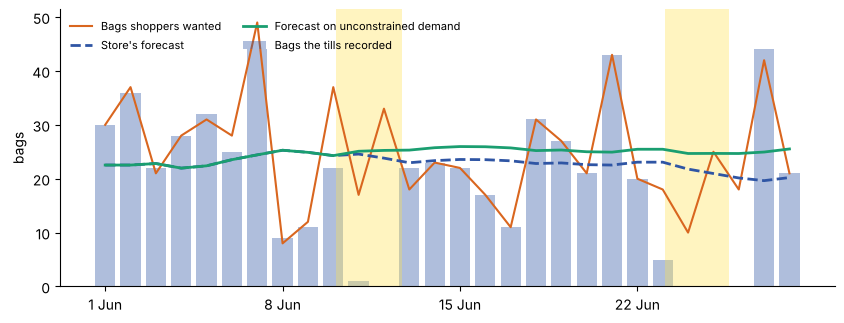

In [9]:
import matplotlib.pyplot as plt
base5 = truth[truth.sku == HERO].sort_values("date").base_demand.to_numpy()
x = np.arange(28)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(x, daily[HERO][28:], color="#2f55a4", alpha=0.38, label="Bags the tills recorded")
ax.plot(x, base5, color="#d9661f", lw=1.5, label="Bags shoppers wanted")
ax.plot(x, made[HERO][27:55], color="#2f55a4", ls="--", lw=2, label="Store's forecast")
ax.plot(x, forecast_aware[HERO][27:55], color="#1a9e70", lw=2, label="Forecast on unconstrained demand")
for r in [r for r in runs if r["sku"] == HERO]:
    a, b = r["hours"][0], r["hours"][-1]
    ax.axvspan(a[0] + a[1] / 15 - 0.5, b[0] + (b[1] + 1) / 15 - 0.5, color="#ffe14d", alpha=0.35, lw=0)
ax.set_xticks(x[::7], [JUNE_DAYS[i].strftime("%-d %b") for i in x[::7]])
ax.set_ylabel("bags"); ax.legend(ncol=2, fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 6. Availability, five ways

Three measures from the records, two from the answer key.

In [10]:
open_june = 28 * 15
hero_censored = sum(len(r["hours"]) for r in runs if r["sku"] == HERO) + sum(s == HERO for s, _, _ in stockouts)
t5 = truth[truth.sku == HERO]
audits5 = tables["shelf_audits"].query("sku == @HERO")
{
    "on the books": round(float((book[HERO] > 0).mean()), 3),
    "shelf audits": round(float((audits5.status == "on shelf").mean()), 3),
    "books and tills": round(1 - hero_censored / open_june, 3),       # stock on the books, outside the gaps
    "on the shelf (answer key)": round(float(1 - t5.empty_open_hours.sum() / open_june), 3),
    "demand served (answer key)": round(float(1 - t5.lost.sum() / t5.true_demand.sum()), 3),
}

{'on the books': 0.969,
 'shelf audits': 0.75,
 'books and tills': 0.786,
 'on the shelf (answer key)': 0.768,
 'demand served (answer key)': 0.781}

## 7. The assistant, with and without a domain layer

The question at the heart of the post, answered the way a text-to-SQL assistant would with the schema only, then
with the domain layer: definitions, the till lines and shelf audits, and views built from them. The data is cut at
Sunday 14 June: the assistant answers at the Monday review.

In [11]:
AS_OF, W1, W2 = "2026-06-14", "'2026-06-01' AND '2026-06-07'", "'2026-06-08' AND '2026-06-14'"
weeks = q(f"""SELECT sum(CASE WHEN date BETWEEN {W1} THEN units_sold END) AS week1,
                     sum(CASE WHEN date BETWEEN {W2} THEN units_sold END) AS week2
              FROM daily_sales WHERE sku = '{HERO}'""").iloc[0]
books_w2 = q(f"SELECT min(book_on_hand_close) AS low, max(book_on_hand_close) AS high FROM inventory_book "
             f"WHERE sku = '{HERO}' AND date BETWEEN {W2}").iloc[0]
share = q(f"""SELECT sum(CASE WHEN sku = '{HERO}' AND date BETWEEN {W1} THEN units_sold END)
                       / sum(CASE WHEN date BETWEEN {W1} THEN units_sold END) AS week1,
                     sum(CASE WHEN sku = '{HERO}' AND date BETWEEN {W2} THEN units_sold END)
                       / sum(CASE WHEN date BETWEEN {W2} THEN units_sold END) AS week2
              FROM daily_sales WHERE sku LIKE 'ATTA%'""").iloc[0]
print("Schema only:", f"Sales fell {1 - weeks.week2 / weeks.week1:.0%}, from {int(weeks.week1)} bags to {int(weeks.week2)}. "
      f"The books showed {int(books_w2.low)} to {int(books_w2.high)} bags on hand all week, so stock was available. "
      f"5 kg's share of atta fell from {share.week1:.0%} to {share.week2:.0%}, which suggests shoppers are moving to other pack sizes.")

Schema only: Sales fell 59%, from 217 bags to 88. The books showed 33 to 78 bags on hand all week, so stock was available. 5 kg's share of atta fell from 40% to 25%, which suggests shoppers are moving to other pack sizes.


In [12]:
# The domain layer: censored hours as of the review (the runs the detector had flagged, and the hours with no stock
# on the books), and a demand estimate built on them.
flagged = [r for r in runs if ts(r["flag"]) <= "2026-06-15T09:00"]
cens = pd.DataFrame([{"sku": r["sku"], "run_start": ts(r["start"]), "date": JUNE_DAYS[d].isoformat(), "hour": OPEN_HOURS[0] + h,
                      "expected": e, "recorded": rec} for r in flagged for d, h, e, rec in r["hours"]]
                    + [{"sku": s, "run_start": None, "date": JUNE_DAYS[d].isoformat(), "hour": OPEN_HOURS[0] + h,
                        "expected": expected_sales(s, d, h), "recorded": june[s][d, h]} for s, d, h in stockouts])
cens = cens[cens.date <= AS_OF]
con.register("v_censored_hours", cens)
def imputed(s, day):
    c = cens[(cens.sku == s) & (cens.date == day)]
    return float((c.expected - c.recorded).clip(lower=0).sum())

est = pd.DataFrame([{"date": d.isoformat(), "sku": s, "recorded": daily[s][28 + j], "imputed": imputed(s, d.isoformat())}
                    for s in DC for j, d in enumerate(JUNE_DAYS) if d.isoformat() <= AS_OF])
est["demand_estimate"] = est.recorded + est.imputed
con.register("v_demand_estimate", est)

gap = q(f"""SELECT run_start, count(*) AS open_hours, CAST(sum(recorded) AS INTEGER) AS recorded, round(sum(expected)) AS expected
            FROM v_censored_hours WHERE sku = '{HERO}' AND date BETWEEN {W2} GROUP BY run_start ORDER BY open_hours DESC LIMIT 1""").iloc[0]
audit = q(f"SELECT audit_ts, status FROM shelf_audits WHERE sku = '{HERO}' AND CAST(audit_ts AS DATE) BETWEEN {W2} AND status = 'empty'")
split = q(f"""SELECT CASE WHEN date <= '2026-06-07' THEN 'week1' ELSE 'week2' END AS week, sum(recorded) AS recorded,
                     round(sum(demand_estimate)) AS with_gaps_filled FROM v_demand_estimate WHERE sku = '{HERO}' GROUP BY ALL ORDER BY week""")
display(gap.to_frame().T, audit, split)
print("With the domain layer:", f"{gap.open_hours} open hours with {gap.recorded} bag recorded against {int(gap.expected)} expected, "
      f"while the books showed stock; the shelf audit at {audit.audit_ts.iloc[0]:%a %-d %b %H:%M} found the bay empty. "
      f"With those hours filled in the week comes to about {int(split.with_gaps_filled.iloc[1])} bags against "
      f"{int(split.with_gaps_filled.iloc[0])}: the empty shelf explains about half the fall.")

,run_start,open_hours,recorded,expected
0,2026-06-10T16:00,39,1,68.0


,audit_ts,status
0,2026-06-12 11:00:00,empty


,week,recorded,with_gaps_filled
0,week1,217.0,217.0
1,week2,88.0,155.0


With the domain layer: 39 open hours with 1 bag recorded against 68 expected, while the books showed stock; the shelf audit at Fri 12 Jun 11:00 found the bay empty. With those hours filled in the week comes to about 155 bags against 217: the empty shelf explains about half the fall.


### Try it on your own model

The two prompts below hold everything each assistant was given. Paste either into a model of your choice with one of
the seven questions from the companion, and compare its answer with the answer key.

In [13]:
schema = "\n".join(f"{t}({', '.join(tables[t].columns)})" for t in ["daily_sales", "inventory_book", "forecasts", "store_orders", "products"])
domain_layer = """definitions:
  sales: Units the tills scanned. Sales measure demand only while the item is on the shelf.
  book_stock: What the system believes is on hand. A belief, not an observation.
  shelf_audit: A person looked at the shelf. An observation.
  demand: Sales plus the sales expected in censored hours.
rules:
  - Treat as censored every open hour with no stock on the books, and every run of no sales longer than the item's usual rate allows while the books show stock.
  - If sales resume without a delivery, the stock was in the store all along.
  - Never compare sales across periods without removing censored hours.
views: v_hourly_sales, v_hourly_book, v_censored_hours(sku, run_start, date, hour, expected, recorded), v_demand_estimate
tables_added: pos_lines, shelf_audits, goods_receipts, stock_counts"""
print("PROMPT, SCHEMA ONLY\n" + schema)
print("\nPROMPT, WITH THE DOMAIN LAYER\n" + schema + "\n" + domain_layer)

PROMPT, SCHEMA ONLY
daily_sales(date, sku, units_sold, revenue_inr)
inventory_book(date, sku, book_on_hand_close)
forecasts(date, sku, forecast_units_per_day, sigma, reorder_point, order_up_to, book_on_hand, on_order, ordered_units, method)
store_orders(order_id, sku, units, cases, created_ts, reason)
products(sku, gtin, name, pack, case_units, case_kg, flow, dc_slot, price_inr, cost_inr)

PROMPT, WITH THE DOMAIN LAYER
daily_sales(date, sku, units_sold, revenue_inr)
inventory_book(date, sku, book_on_hand_close)
forecasts(date, sku, forecast_units_per_day, sigma, reorder_point, order_up_to, book_on_hand, on_order, ordered_units, method)
store_orders(order_id, sku, units, cases, created_ts, reason)
products(sku, gtin, name, pack, case_units, case_kg, flow, dc_slot, price_inr, cost_inr)
definitions:
  sales: Units the tills scanned. Sales measure demand only while the item is on the shelf.
  book_stock: What the system believes is on hand. A belief, not an observation.
  shelf_audit: A pe

## Exercises

1. Find the hours when an item sold nothing while the hourly book showed a full shelf's worth.
2. Run the detector at 1 in 100 and 1 in 10,000 and plot alerts in real gaps against gaps found.
3. Replace the Poisson zero with a negative binomial whose dispersion you estimate from May. Fewer false alarms?
4. Estimate toned milk's demand above the sell-out, from each day's last sale (`pos_lines`) and the morning's
   delivery (`fresh_deliveries`).
5. Give the domain layer to a model of your choice and ask the seven questions from the companion.

The answer key (`answer-key-retail.json`) scores each one.

In [14]:
# The numbers the post quotes, in one place.
summary = {
    "generic_tests_passed": int(sum(v == 0 for v in results.values())),
    "domain_audits": len(empty_with_stock), "flags": len(runs),
    "hourly_1_in_1000": options["hourly, 1 in 1,000"],
    "hero_month_end": {"naive": round(float(made[HERO][-1]), 1), "aware": round(float(forecast_aware[HERO][-1]), 1)},
}
print(json.dumps(summary, default=str))

{"generic_tests_passed": 11, "domain_audits": 2, "flags": 10, "hourly_1_in_1000": {"alerts": 10, "in a real gap": 6, "gaps found": "6 of 10", "median open hours to alert": 3.67}, "hero_month_end": {"naive": 20.2, "aware": 25.6}}
